# Temă LP3 — Preprocesarea datelor (Titanic)

**Timp de lucru: maximum 15 minute** · lucru individual

Aplicați tehnicile din LP3 pe un set de date nou: **Titanic** — informații despre pasagerii navei (vârstă, sex, preț bilet, port de îmbarcare, punte) și dacă au supraviețuit (`survived`).

| Sarcina | Tema | Timp |
| --- | --- | --- |
| 1 | Valori lipsă: diagnostic și eliminare pe bază de prag | ~3 min |
| 2 | Imputarea valorilor lipsă | ~3 min |
| 3 | Asimetrie și transformare logaritmică | ~3 min |
| 4 | Outlieri (regula IQR) | ~3 min |
| 5 | Encoding și scalare | ~3 min |

> 💡 Completați celulele marcate `# TODO`. Nu e nevoie de cod perfect — contează să înțelegeți ce face fiecare pas.

### Pregătire — rulați celula (nu necesită modificări)

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

titanic = sns.load_dataset('titanic')
df = titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'deck']].copy()
df.head()

,survived,pclass,sex,age,fare,embarked,deck
0,0,3,male,22.0,7.2500,S,NaN
1,1,1,female,38.0,71.2833,C,C
2,1,3,female,26.0,7.9250,S,NaN
3,1,1,female,35.0,53.1000,S,C
4,0,3,male,35.0,8.0500,S,NaN


## Sarcina 1 — Valori lipsă (~3 min)

**1.1** Calculați procentul de valori lipsă pentru fiecare coloană, sortat descrescător.

**1.2** Eliminați coloanele cu **mai mult de 50%** valori lipsă. Care coloană dispare?

In [29]:
# TODO 1.1 — procentul de valori lipsă pe coloană
procent_lipsa = df.isna().mean() * 100
proc_desc = procent_lipsa.sort_values(ascending=False)
print(proc_desc)

# TODO 1.2 — eliminați coloanele cu > 50% valori lipsă
col_drop = proc_desc[proc_desc > 50].index
df = df.drop(col_drop, axis=1)
df.head()

deck        77.216611
age         19.865320
embarked     0.224467
sex          0.000000
pclass       0.000000
survived     0.000000
fare         0.000000
dtype: float64


,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


## Sarcina 2 — Imputarea valorilor lipsă (~3 min)

**2.1** Imputați `age` cu **mediana** și `embarked` cu **valoarea cea mai frecventă** (modul).

**2.2** Verificați că nu mai există valori lipsă și comparați deviația standard a lui `age` înainte și după imputare. *(salvați înainte de imputare: `age_inainte = df['age'].copy()`)*

In [30]:
# TODO 2.1 — imputare age (mediană) și embarked (mod)
age_inainte = df['age'].copy()
age = df['age'].fillna(df['age'].median())
embarked = df['embarked'].fillna(df['embarked'].mode()[0])
df['age'] = age
df['embarked'] = embarked

# TODO 2.2 — verificare + comparație deviație standard
procent_lipsa = df.isna().mean() * 100
print(procent_lipsa)
print(age_inainte.std())
print(df['age'].std())

survived    0.0
pclass      0.0
sex         0.0
age         0.0
fare        0.0
embarked    0.0
dtype: float64
14.526497332334044
13.019696550973194


## Sarcina 3 — Asimetrie și transformare logaritmică (~3 min)

**3.1** Calculați skewness-ul variabilei `fare`.

**3.2** Creați coloana `log_fare = np.log1p(fare)` și calculați skewness-ul ei. A ajutat transformarea?

**3.3** Desenați cele două histograme una lângă alta.

4.787316519674893
0.3949280095189306


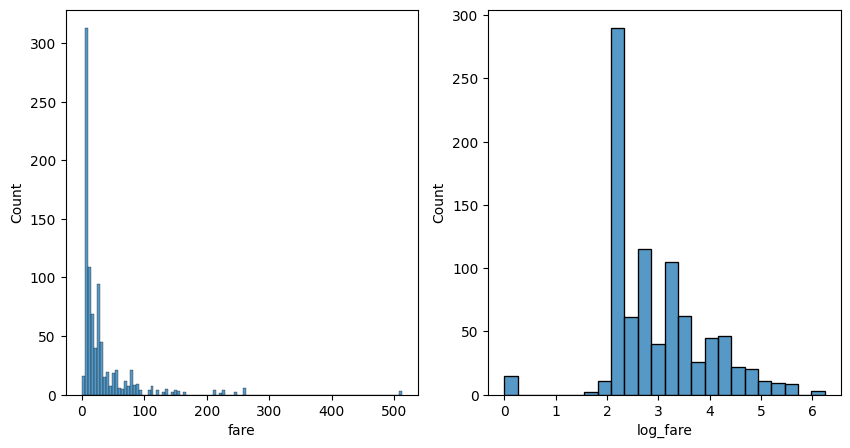

In [31]:
# TODO 3.1 — skewness fare
skewn = df['fare'].skew()
print(skewn)

# TODO 3.2 — coloana log_fare + skewness
df['log_fare'] = np.log1p(df['fare'])
skewn = df['log_fare'].skew()
print(skewn)

# TODO 3.3 — două histograme
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
sns.histplot(df['fare'], ax=axs[0])
sns.histplot(df['log_fare'], ax=axs[1])
plt.show()

## Sarcina 4 — Outlieri cu regula IQR (~3 min)

**4.1** Calculați limitele `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` pentru `fare` și numărați outlierii.

**4.2** Limitați (clip) valorile extreme într-o coloană nouă, `fare_capped`, și afișați maximul înainte și după.

In [32]:
# TODO 4.1 — limite IQR + număr de outlieri
def limite(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    limite = [float(Q1 - 1.5 * IQR), float(Q3 + 1.5 * IQR)]
    outlier = df[(df[col] < limite[0]) | (df[col] > limite[1])]
    return limite, outlier.shape[0]

limite, outlier = limite(df, 'fare')
print(limite)
print(outlier)

# TODO 4.2 — fare_capped (clip) + maxim înainte/după

df['fare_capped'] = df['fare'].clip(limite[0], limite[1])
print(df['fare'].max())
print(df['fare_capped'].max())

[-26.724, 65.6344]
116
512.3292
65.6344


## Sarcina 5 — Encoding și scalare (~3 min)

**5.1** Aplicați One-Hot Encoding pe `sex` și `embarked` (cu `drop_first=True`, `dtype=int`).

**5.2** Standardizați `age` și `fare_capped` cu `StandardScaler`. Verificați că media ≈ 0 și deviația standard ≈ 1.

In [33]:
# TODO 5.1 — One-Hot Encoding pentru sex și embarked
sex = pd.get_dummies(df['sex'], drop_first=True, dtype=int)
embarked = pd.get_dummies(df['embarked'], drop_first=True, dtype=int)
print(df.head())
df = pd.concat([df, sex, embarked], axis=1)
df = df.drop(['sex', 'embarked'], axis=1)
print(df.head())

# TODO 5.2 — StandardScaler pentru age și fare_capped + verificare medie/std
scaler = StandardScaler()
df['age'] = scaler.fit_transform(df[['age']])
df['fare_capped'] = scaler.fit_transform(df[['fare_capped']])
print(df.head())
print(df['age'].mean())
print(df['age'].std())
print(df['fare_capped'].mean())
print(df['fare_capped'].std())

   survived  pclass     sex   age     fare embarked  log_fare  fare_capped
0         0       3    male  22.0   7.2500        S  2.110213       7.2500
1         1       1  female  38.0  71.2833        C  4.280593      65.6344
2         1       3  female  26.0   7.9250        S  2.188856       7.9250
3         1       1  female  35.0  53.1000        S  3.990834      53.1000
4         0       3    male  35.0   8.0500        S  2.202765       8.0500
   survived  pclass   age     fare  log_fare  fare_capped  male  Q  S
0         0       3  22.0   7.2500  2.110213       7.2500     1  0  1
1         1       1  38.0  71.2833  4.280593      65.6344     0  0  0
2         1       3  26.0   7.9250  2.188856       7.9250     0  0  1
3         1       1  35.0  53.1000  3.990834      53.1000     0  0  1
4         0       3  35.0   8.0500  2.202765       8.0500     1  0  1
   survived  pclass       age     fare  log_fare  fare_capped  male  Q  S
0         0       3 -0.565736   7.2500  2.110213    -0.8

## Întrebare de reflecție (1–2 propoziții)

*De ce am imputat `age`, dar am eliminat `deck`?*

*Răspunsul tău: Am imputat age datorita numarului mai mic de valori lipsa, acesta permitand o imputare fara sa se schimbe prea mult media, iar deck a fost eliminat deoarece avea un procent de 77% date lipsa si o eventuala imputare ar fi indus modelul in eroare.*